In [17]:
# in this notebook we will look at some other features (we have only looked at feature 5712 in the first two notebooks)
# i want to see if we can find some features which correspond to some interesting biological concepts, not just an amino acid residue like before

Load the archive created by the save cell in notebook 02 before exploring another layer-4 feature.
No sequence downloads or model inference are needed here. Sequences are restored as `amino_acid_dict` strings, alongside the embedding and activation dictionaries and their metadata.
All feature columns are available: `activations_by_protein[accession][:, feature_id]` selects the feature to investigate.

In [18]:
from functools import partial

import numpy as np
import matplotlib.pyplot as plt

import importlib
import helper

importlib.reload(helper)
from helper import load_analysis, summarise_activations

In [19]:
(
    amino_acid_dict,
    embeddings_by_protein,
    activations_by_protein,
    analysis_metadata,
) = load_analysis("data/processed/esm2_8m_layer4_development.npz")

model_settings = analysis_metadata["model_settings"]
layer = model_settings["layer"]
assert layer == 4, f"Expected layer 4, found layer {layer}."

# Keep the same two-argument summary calls as notebook 02.
summarise_activations = partial(
    summarise_activations,
    amino_acid_dict=amino_acid_dict,
    activations_by_protein=activations_by_protein,
)

print(
    f"Loaded {len(amino_acid_dict)} proteins from {model_settings['plm_model']}, "
    f"layer {layer}; SAE feature IDs 0–{model_settings['sae_dict_size'] - 1}."
)

Loaded 6 proteins from facebook/esm2_t6_8M_UR50D, layer 4; SAE feature IDs 0–10239.


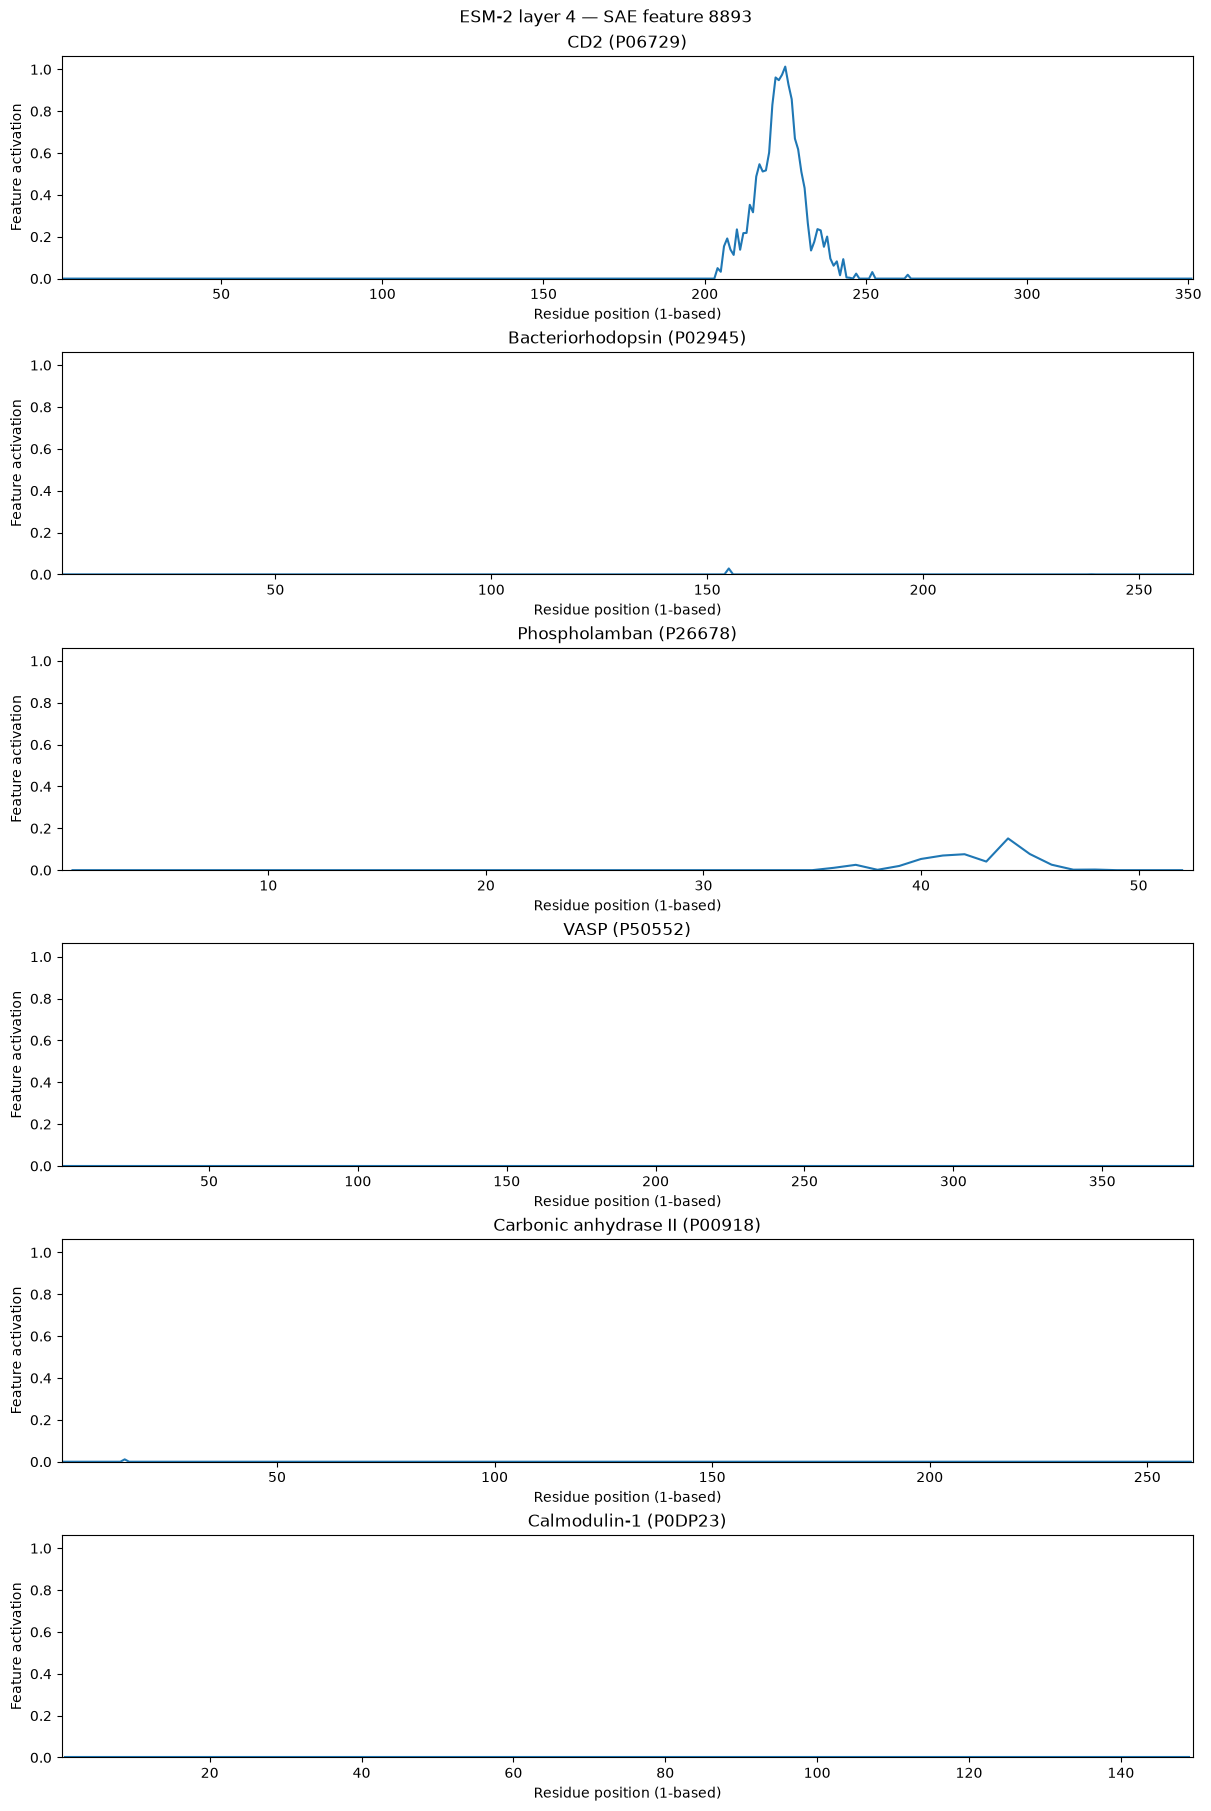

In [20]:
# Compare the same SAE feature across all six development proteins.
feature_id = 8893
protein_names = {
    'P06729': 'CD2',
    'P02945': 'Bacteriorhodopsin',
    'P26678': 'Phospholamban',
    'P50552': 'VASP',
    'P00918': 'Carbonic anhydrase II',
    'P0DP23': 'Calmodulin-1',
}

fig, axes = plt.subplots(
    nrows=6, ncols=1, figsize=(12, 18),
    sharey=True, constrained_layout=True,
)
fig.suptitle(f"ESM-2 layer {layer} — SAE feature {feature_id}")

for ax, (accession, protein_name) in zip(axes, protein_names.items()):
    sequence = amino_acid_dict[accession]
    protein_activations = activations_by_protein[accession]
    positions = np.arange(1, len(sequence) + 1)

    ax.plot(positions, protein_activations[:, feature_id])
    ax.set(
        xlabel="Residue position (1-based)",
        ylabel="Feature activation",
        title=f"{protein_name} ({accession})",
        xlim=(0.5, len(sequence) + 0.5),
    )

# Use a common y-axis scale to compare activation strengths.
axes[0].set_ylim(bottom=0)
plt.show();

In [21]:
from functools import partial
from helper import summarise_activations

# Bind the data once so calls still need only the accession and feature ID.
summarise_activations = partial(
    summarise_activations,
    amino_acid_dict=amino_acid_dict,
    activations_by_protein=activations_by_protein,
)

In [22]:
# Print one feature-5712 summary table for each of the six proteins.
for accession in amino_acid_dict:
    summarise_activations(accession, feature_id=feature_id)
    print()  # Separate the tables with a blank line.

P06729 — feature 8893; activation statistics ×100 (not percentages)
            Count    Mean     Q1  Median      Q3
Amino acid                                      
A              16  4.1816 0.0000  0.0000  0.0000
C               6  9.1104 0.0000  0.0000  0.0000
D              17  0.6664 0.0000  0.0000  0.0000
E              19  0.3000 0.0000  0.0000  0.0000
F              12  9.9355 0.0000  0.0000  0.0000
G              19 11.2654 0.0000  0.0000  9.5931
H              12  0.0000 0.0000  0.0000  0.0000
I              21  7.0003 0.0000  0.0000  0.0000
K              39  1.7472 0.0000  0.0000  0.0000
L              25 13.5760 0.0000  0.0000  0.0000
M               4 24.3512 0.0000  0.0000 24.3512
N              13  0.0317 0.0000  0.0000  0.0000
P              32  0.1563 0.0000  0.0000  0.0000
Q              19  0.3250 0.0000  0.0000  0.0000
R              17  2.2511 0.0000  0.0000  1.8415
S              29  2.9173 0.0000  0.0000  0.0000
T              23  1.0286 0.0000  0.0000  0.0000
V